# EDA singkat data OLIST (#5)

Bahan presentasi bagian data dan dasar aturan agent SQL. Semua angka dibaca dari `data/olist.db` hasil ETL (`scripts/build_sqlite.py`), kecuali teks review yang dibaca dari CSV mentah karena tidak masuk SQL. Kamus kolom ada di `docs/KAMUS-DATA.md`.

Menjalankan ulang:

```sh
uv sync --group eda
uv run jupyter execute notebooks/eda_olist.ipynb   # atau buka di editor notebook
```

Gambar disimpan ke `docs/eda/` untuk dipakai di slide.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
GAMBAR = ROOT / "docs" / "eda"
GAMBAR.mkdir(parents=True, exist_ok=True)
conn = sqlite3.connect(f"file:{ROOT / 'data' / 'olist.db'}?mode=ro", uri=True)
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sql(q: str) -> pd.DataFrame:
    return pd.read_sql_query(q, conn)


def simpan(nama: str) -> None:
    plt.tight_layout()
    plt.savefig(GAMBAR / f"{nama}.png", bbox_inches="tight")
    plt.show()


sql(
    "SELECT MIN(tanggal_beli) AS awal, MAX(tanggal_beli) AS akhir, COUNT(*) AS pesanan FROM v_order"
)

,awal,akhir,pesanan
0,2016-09-04 21:15:19,2018-10-17 17:30:18,99441


## 1. Sebaran harga dan ongkir

Per item terjual (`v_item_terjual`). Sumbu x memakai skala log karena harga sangat menceng ke kanan.

       harga_brl  ongkir_brl
count  112101.00   112101.00
mean      120.38       19.99
std       182.64       15.80
min         0.85        0.00
50%        74.90       16.27
90%       229.00       34.04
99%       889.00       84.44
max      6735.00      409.68


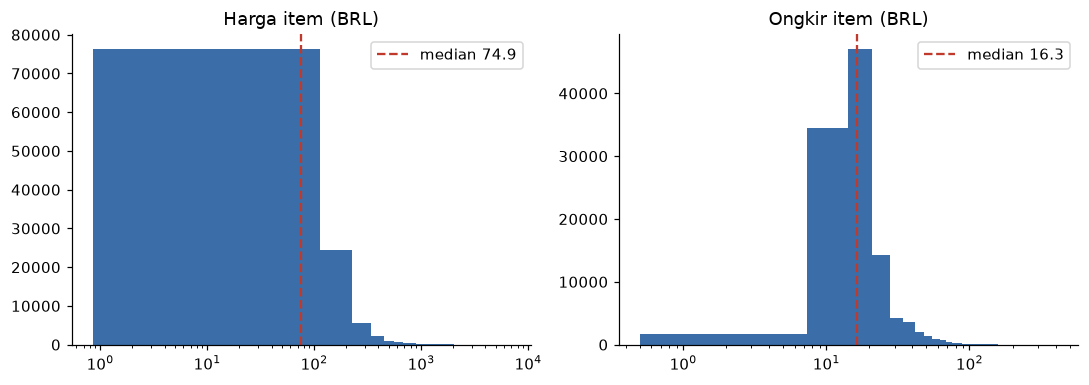

Median ongkir 23% dari harga item.


In [2]:
item = sql("SELECT harga_brl, ongkir_brl FROM v_item_terjual")
print(item.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
judul_kolom = {"harga_brl": "Harga item (BRL)", "ongkir_brl": "Ongkir item (BRL)"}
for a, (kolom, judul) in zip(ax, judul_kolom.items(), strict=True):
    a.hist(item[kolom].clip(lower=0.5), bins=60, color="#3b6ea8")
    a.set_xscale("log")
    a.set_title(judul)
    median = item[kolom].median()
    a.axvline(median, color="#c0392b", linestyle="--", label=f"median {median:.1f}")
    a.legend()
simpan("harga_ongkir")
rasio = (item["ongkir_brl"] / item["harga_brl"]).median()
print(f"Median ongkir {rasio:.0%} dari harga item.")

## 2. Waktu kirim dibanding estimasi

Dari tabel `orders` mentah, karena estimasi tidak masuk view. Selisih negatif berarti tiba lebih cepat dari estimasi.

Rata-rata lama kirim 12.6 hari.
Rata-rata estimasi 23.7 hari.
Rata-rata tiba 11.9 hari lebih cepat dari estimasi.
Terlambat 6.8%.


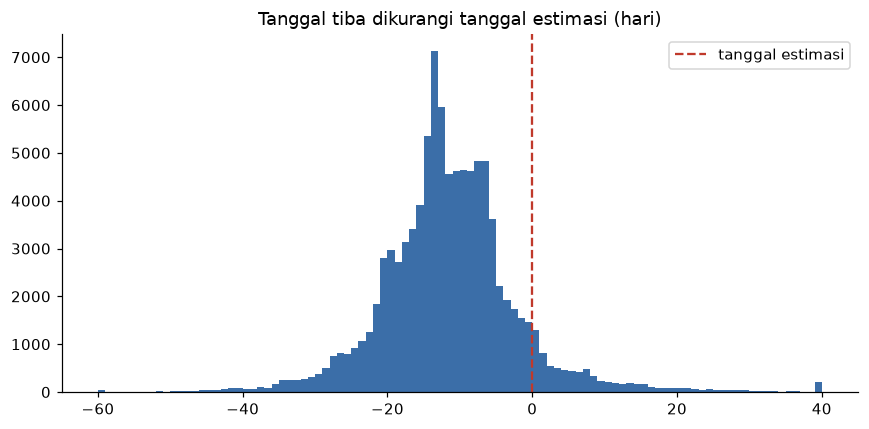

In [3]:
kirim = sql("""
SELECT julianday(order_delivered_customer_date)
         - julianday(order_purchase_timestamp) AS hari_kirim,
       julianday(order_estimated_delivery_date)
         - julianday(order_purchase_timestamp) AS hari_estimasi,
       julianday(date(order_delivered_customer_date))
         - julianday(date(order_estimated_delivery_date)) AS selisih
FROM orders WHERE order_delivered_customer_date IS NOT NULL
""")
terlambat = (kirim["selisih"] > 0).mean()
print(f"Rata-rata lama kirim {kirim.hari_kirim.mean():.1f} hari.")
print(f"Rata-rata estimasi {kirim.hari_estimasi.mean():.1f} hari.")
print(f"Rata-rata tiba {-kirim.selisih.mean():.1f} hari lebih cepat dari estimasi.")
print(f"Terlambat {terlambat:.1%}.")
plt.hist(kirim["selisih"].clip(-60, 40), bins=100, color="#3b6ea8")
plt.axvline(0, color="#c0392b", linestyle="--", label="tanggal estimasi")
plt.title("Tanggal tiba dikurangi tanggal estimasi (hari)")
plt.legend()
simpan("kirim_vs_estimasi")

## 3. Sebaran skor review

 skor  jumlah  persen
    1   11424    11.5
    2    3151     3.2
    3    8179     8.2
    4   19142    19.3
    5   57328    57.8


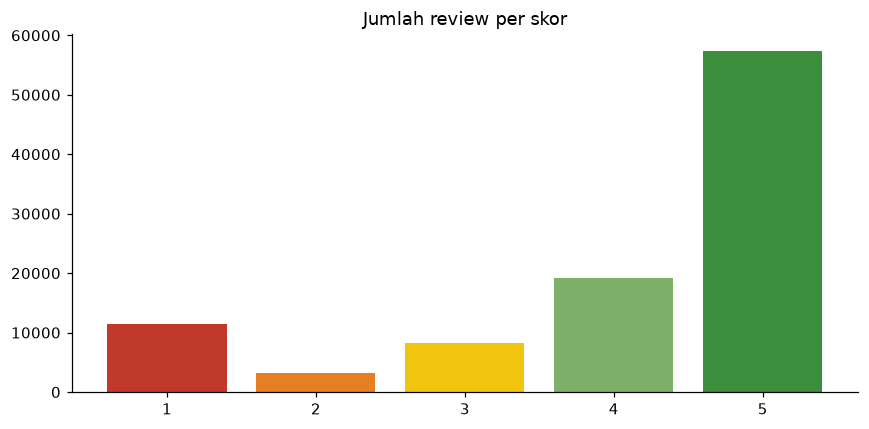

Review tanpa teks 58.7% dari 99,224.


In [4]:
skor = sql(
    "SELECT review_score AS skor, COUNT(*) AS jumlah FROM order_reviews GROUP BY 1 ORDER BY 1"
)
skor["persen"] = (100 * skor.jumlah / skor.jumlah.sum()).round(1)
print(skor.to_string(index=False))
plt.bar(
    skor.skor.astype(str),
    skor.jumlah,
    color=["#c0392b", "#e67e22", "#f1c40f", "#7fb069", "#3b8e3b"],
)
plt.title("Jumlah review per skor")
simpan("skor_review")
csv_review = ROOT / "data" / "raw" / "olist_order_reviews_dataset.csv"
teks = pd.read_csv(csv_review, usecols=["review_comment_message"])
print(f"Review tanpa teks {teks.review_comment_message.isna().mean():.1%} dari {len(teks):,}.")

## 4. Kategori terlaris

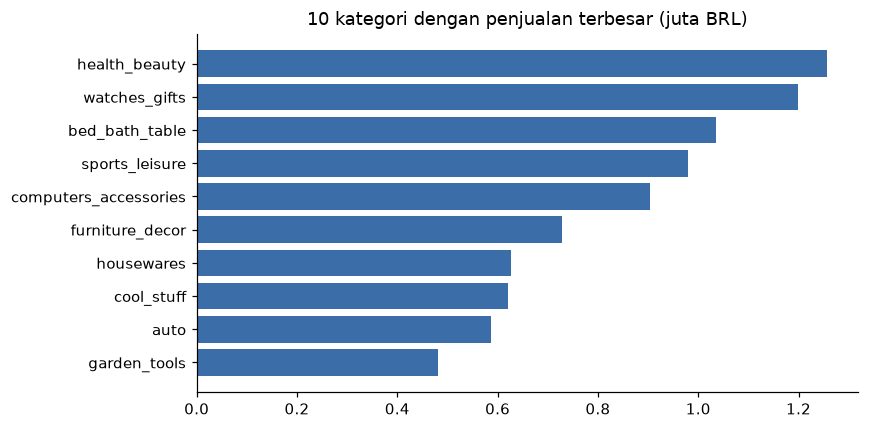

             kategori  jumlah_order  total_penjualan_brl  rata_skor  persen_terlambat
        health_beauty          8800           1255695.13       4.19               7.5
        watches_gifts          5604           1198185.21       4.07               7.4
       bed_bath_table          9399           1035964.06       3.97               7.4
       sports_leisure          7673            979740.92       4.18               6.6
computers_accessories          6654            904322.02       4.04               6.4
      furniture_decor          6425            727465.05       4.02               7.1
           housewares          5847            626825.80       4.16               5.4
           cool_stuff          3616            620770.49       4.18               5.9
                 auto          3872            586585.73       4.11               7.3
         garden_tools          3505            481009.94       4.15               6.5
10 kategori teratas memegang 62% penjualan.


In [5]:
kat = sql(
    "SELECT kategori, jumlah_order, total_penjualan_brl, rata_skor, persen_terlambat "
    "FROM v_ringkasan_kategori ORDER BY total_penjualan_brl DESC"
)
top = kat.head(10).iloc[::-1]
plt.barh(top.kategori, top.total_penjualan_brl / 1e6, color="#3b6ea8")
plt.title("10 kategori dengan penjualan terbesar (juta BRL)")
simpan("kategori_terlaris")
print(kat.head(10).to_string(index=False))
porsi = kat.head(10).total_penjualan_brl.sum() / kat.total_penjualan_brl.sum()
print(f"10 kategori teratas memegang {porsi:.0%} penjualan.")

## 5. Keterlambatan dan skor review

Temuan paling penting untuk produk: alasan utama skor buruk adalah keterlambatan, bukan harga. Ini dasar pertanyaan hybrid seperti "kategori apa yang paling sering terlambat, dan apa kata pembelinya?".

     status  pesanan  rata_skor  persen_skor_1_2
tepat waktu    89448       4.29              9.2
  terlambat     6382       2.27             62.3


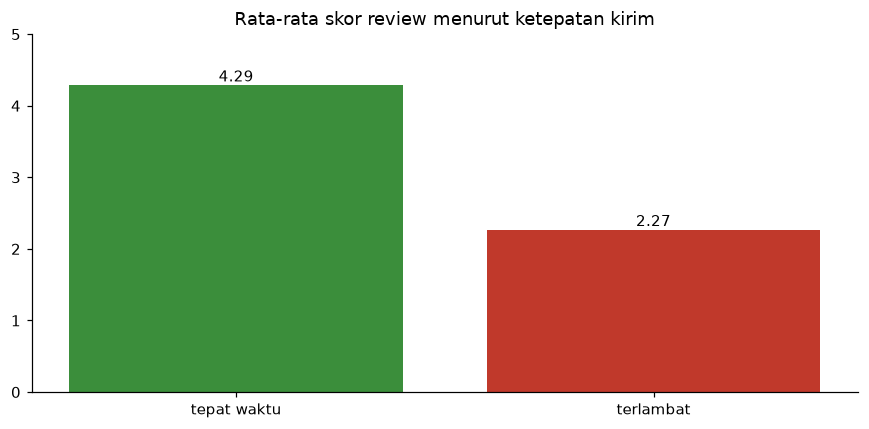

In [6]:
tl = sql(
    "SELECT terlambat, ROUND(AVG(skor), 2) AS rata_skor, COUNT(*) AS pesanan, "
    "ROUND(100.0 * AVG(skor <= 2), 1) AS persen_skor_1_2 FROM v_order "
    "WHERE terlambat IS NOT NULL AND skor IS NOT NULL GROUP BY 1"
)
tl["status"] = tl.terlambat.map({0: "tepat waktu", 1: "terlambat"})
print(tl[["status", "pesanan", "rata_skor", "persen_skor_1_2"]].to_string(index=False))
plt.bar(tl.status, tl.rata_skor, color=["#3b8e3b", "#c0392b"])
for i, v in enumerate(tl.rata_skor):
    plt.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.ylim(0, 5)
plt.title("Rata-rata skor review menurut ketepatan kirim")
simpan("terlambat_vs_skor")

## 6. Penjualan per bulan

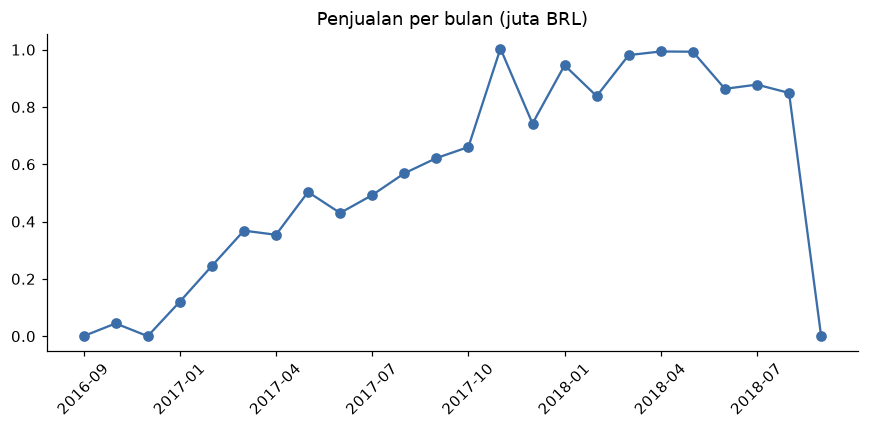

  bulan  pesanan  penjualan
2016-09        2     207.86
2016-10      290   44507.30
2016-12        1      10.90
...
  bulan  pesanan  penjualan
2018-07     6233  878044.27
2018-08     6421  848860.10
2018-09        1     145.00


In [7]:
bulan = sql(
    "SELECT strftime('%Y-%m', tanggal_beli) AS bulan, COUNT(DISTINCT order_id) AS pesanan, "
    "SUM(harga_brl) AS penjualan FROM v_item_terjual GROUP BY 1 ORDER BY 1"
)
plt.plot(bulan.bulan, bulan.penjualan / 1e6, marker="o", color="#3b6ea8")
plt.xticks(bulan.bulan[::3], rotation=45)
plt.title("Penjualan per bulan (juta BRL)")
simpan("penjualan_bulanan")
print(bulan.head(3).to_string(index=False))
print("...")
print(bulan.tail(3).to_string(index=False))

## Kesimpulan untuk agent dan presentasi

1. **Data historis 2016 sampai 2018.** Pertanyaan "sekarang" tentang harga atau stok ditolak. Bulan awal dan akhir sangat sedikit pesanannya, jadi tren tepi tidak dipakai sebagai kesimpulan.
2. **Harga menceng ke kanan.** Median lebih jujur daripada rata-rata untuk "harga biasa".
3. **Estimasi kirim longgar.** Rata-rata tiba jauh lebih cepat dari estimasi, sehingga persen terlambat relatif kecil, tetapi dampaknya pada skor sangat besar.
4. **Keterlambatan adalah penyebab utama skor buruk.** Skor rata-rata pesanan terlambat jauh di bawah yang tepat waktu.
5. **Sebagian besar review tanpa teks.** Agent RAG hanya punya contoh dari review berteks, sedangkan statistik skor dari SQL mencakup semua review.
6. **Kategori kecil menipu peringkat.** Peringkat rasio memakai minimal 30 pesanan, ditegakkan di kode agent SQL.